# Session 6: Position and timing errors in the humidity field

**Question:** do the route choices survive errors in *where* and *when* the supersaturated air is, rather than how humid it is?

**Builds on:** Session 5's uniform humidity scaling makes every route wetter or drier together, so it tends to keep their ranking. Position and timing errors could instead make a "dry side" detour fly into moist air.

**Approach:**
1. Move the whole ERA5 temperature and humidity field over the region and re-evaluate the 40 Session 4 routes:
   - `shift_0`: no displacement (check: must reproduce Session 4)
   - `field_NW50`, `field_NW100`: 50/100 km towards the north-west, the side the detours use
   - `field_SE50`, `field_SE100`: 50/100 km towards the south-east
   - `field_fwd100`, `field_back100`: 100 km along / against the direction of flight
   - `time_minus1h`: the weather arrives 1 hour early (the field at time t is ERA5 at t + 1 h)
2. Find the best route in each scenario, and apply the Session 5 decision rules to these scenarios and to all Session 5–6 scenarios combined.

**Assumptions:** as Session 4. Fuel is kept at the Session 4 (undisplaced) values: these scenarios test where contrail-forming air is, not fuel.

**Sections:** 1. Setup and regional data · 2. Displacement scenarios · 3. All scenarios · 4. Exposure and the best route per scenario · 5. Robust choice across Sessions 5–6 · 6. Figures · Results

> **Note:** fuel values in this notebook were later found to be slightly biased; see *Corrections* in the results at the end.

## 1. Setup and regional data

The ERA5 field over the region is cut out and loaded into memory, so it can be moved.

In [1]:
import sys, warnings
from pathlib import Path
SRC = (Path("..") / "src").resolve()
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pycontrails import MetDataset

from contrail_routing.geometry import make_route, flight_level_to_m
from contrail_routing.met import load_era5, check_met_box
from contrail_routing.evaluate import evaluate_routes, route_metrics, pareto_mask

warnings.filterwarnings("ignore", message=r"\s*Met data appears to have originated from ECMWF")

results_dir = Path("..") / "results"
fig_dir = results_dir / "figures"
s6_dir = results_dir / "session6"
s6_dir.mkdir(parents=True, exist_ok=True)

ORIGIN, DEST = (-10.0, 45.0), (10.0, 55.0)
DEPARTURE = pd.Timestamp("2022-03-01 00:00")
CRUISE_SPEED_MS = 230.0
FLIGHT_LEVELS = [310, 320, 330, 340, 350, 360, 370, 380]
OFFSETS_KM = [-300, -150, 0, 150, 300]
BOX_LON, BOX_LAT = (-15, 15), (40, 60)

def route_label(offset_km, fl):
    side = "GC" if offset_km == 0 else ("NW" if offset_km > 0 else "SE")
    return f"{side}{abs(offset_km)}_FL{fl}"

specs = {route_label(o, fl): {"offset_km": o, "flight_level": fl,
                              "altitude_m": round(flight_level_to_m(fl), 1)}
         for fl in FLIGHT_LEVELS for o in OFFSETS_KM}
routes = {n: make_route(ORIGIN, DEST, s["offset_km"], s["altitude_m"],
                        DEPARTURE, CRUISE_SPEED_MS, name=n)
          for n, s in specs.items()}

met_full = load_era5(time=("2022-03-01T00", "2022-03-01T06"),
                     pressure_levels=[200, 225, 250, 275, 300])
print(check_met_box(met_full, BOX_LON, BOX_LAT))

# Cut out the region and load it into memory (small: 121 x 81 x 5 x 7 per variable)
box_ds = (met_full.data[["air_temperature", "specific_humidity"]]
          .sel(longitude=slice(*BOX_LON), latitude=slice(*BOX_LAT))
          .load())
print("Box dims:", dict(box_ds.sizes))

m4 = pd.read_csv(results_dir / "session4_route_metrics.csv").set_index("route")
fuel = m4["fuel_kg"]
assert set(routes) == set(fuel.index), "Route names differ from Session 4"
print(f"{len(routes)} routes rebuilt; Session 4 fuel loaded.")

                 time  air_temperature_nan  specific_humidity_nan
0 2022-03-01 00:00:00                    0                      0
1 2022-03-01 01:00:00                    0                      0
2 2022-03-01 02:00:00                    0                      0
3 2022-03-01 03:00:00                    0                      0
4 2022-03-01 04:00:00                    0                      0
5 2022-03-01 05:00:00                    0                      0
6 2022-03-01 06:00:00                    0                      0
Box dims: {'longitude': 121, 'latitude': 81, 'level': 5, 'time': 7}
40 routes rebuilt; Session 4 fuel loaded.


## 2. Displacement scenarios

Shifts are defined relative to the route direction, because the moist band lies roughly along the route. Each shifted field must still cover every route in space and time.

In [2]:
KM_PER_DEG_LAT = 110.57
KM_PER_DEG_LON = 111.32 * np.cos(np.radians(50.0))   # at the route's mid-latitude

# Unit vectors (east, north) along the route and to its left (north-west)
d_e = (DEST[0] - ORIGIN[0]) * KM_PER_DEG_LON
d_n = (DEST[1] - ORIGIN[1]) * KM_PER_DEG_LAT
along = np.array([d_e, d_n]) / np.hypot(d_e, d_n)
left = np.array([-along[1], along[0]])

def shifted_met(ds, east_km=0.0, north_km=0.0, hours=0):
    """Move the whole field: +east_km / +north_km moves features east / north;
    hours = -1 means the weather arrives one hour early."""
    out = ds.assign_coords(
        longitude=ds["longitude"].values + east_km / KM_PER_DEG_LON,
        latitude=ds["latitude"].values + north_km / KM_PER_DEG_LAT,
        time=ds["time"].values + np.timedelta64(hours, "h"),
    )
    return MetDataset(out)

def disp(vec_km, hours=0):
    return {"east_km": float(vec_km[0]), "north_km": float(vec_km[1]), "hours": hours}

DISPLACEMENTS = {
    "shift_0":       disp(np.zeros(2)),
    "field_NW50":    disp(50 * left),
    "field_NW100":   disp(100 * left),
    "field_SE50":    disp(-50 * left),
    "field_SE100":   disp(-100 * left),
    "field_fwd100":  disp(100 * along),
    "field_back100": disp(-100 * along),
    "time_minus1h":  disp(np.zeros(2), hours=-1),
}
print(pd.DataFrame(DISPLACEMENTS).T.round(1))

# Check: a shifted copy covers every route's position and time
for name, d in DISPLACEMENTS.items():
    m = shifted_met(box_ds, **d)
    lon, lat, t = m.data["longitude"].values, m.data["latitude"].values, m.data["time"].values
    print(f"{name:14s} lon {lon.min():6.2f}..{lon.max():5.2f} | lat {lat.min():5.2f}..{lat.max():5.2f} | "
          f"time {pd.Timestamp(t.min()):%H:%M}..{pd.Timestamp(t.max()):%H:%M}")

               east_km  north_km  hours
shift_0            0.0       0.0    0.0
field_NW50       -30.6      39.6    0.0
field_NW100      -61.1      79.1    0.0
field_SE50        30.6     -39.6    0.0
field_SE100       61.1     -79.1    0.0
field_fwd100      79.1      61.1    0.0
field_back100    -79.1     -61.1    0.0
time_minus1h       0.0       0.0   -1.0
shift_0        lon -15.00..15.00 | lat 40.00..60.00 | time 00:00..06:00
field_NW50     lon -15.43..14.57 | lat 40.36..60.36 | time 00:00..06:00
field_NW100    lon -15.85..14.15 | lat 40.72..60.72 | time 00:00..06:00
field_SE50     lon -14.57..15.43 | lat 39.64..59.64 | time 00:00..06:00
field_SE100    lon -14.15..15.85 | lat 39.28..59.28 | time 00:00..06:00
field_fwd100   lon -13.89..16.11 | lat 40.55..60.55 | time 00:00..06:00
field_back100  lon -16.11..13.89 | lat 39.45..59.45 | time 00:00..06:00
time_minus1h   lon -15.00..15.00 | lat 40.00..60.00 | time 23:00..05:00


## 3. All scenarios

320 route evaluations. The zero-shift copy must reproduce Session 4 exactly, which shows that cutting out and rebuilding the field changes nothing by itself.

In [3]:
def run_displacement(name, d):
    path = s6_dir / f"along_track_{name}.csv"
    if path.exists():
        df = pd.read_csv(path, parse_dates=["time"])
        print(f"{name:14s} loaded from disk")
        return {r: g.reset_index(drop=True) for r, g in df.groupby("route", sort=False)}
    print(f"{name:14s} evaluating 40 routes ...")
    tables = evaluate_routes(routes, shifted_met(box_ds, **d))
    pd.concat(tables.values(), ignore_index=True).to_csv(path, index=False)
    return tables

disp_tables = {name: run_displacement(name, d) for name, d in DISPLACEMENTS.items()}

# Regression: zero shift must reproduce Session 4
zero = route_metrics(disp_tables["shift_0"], specs).set_index("route")["pcr_km"]
max_diff = (zero - m4.loc[zero.index, "pcr_km"]).abs().max()
print(f"\nMax |shift_0 - Session 4| pcr_km: {max_diff:.6f}")
assert max_diff < 1e-6
print("Zero-shift scenario matches Session 4.")

shift_0        evaluating 40 routes ...
Evaluated 40 routes, no missing values.
field_NW50     evaluating 40 routes ...
Evaluated 40 routes, no missing values.
field_NW100    evaluating 40 routes ...
Evaluated 40 routes, no missing values.
field_SE50     evaluating 40 routes ...
Evaluated 40 routes, no missing values.
field_SE100    evaluating 40 routes ...
Evaluated 40 routes, no missing values.
field_fwd100   evaluating 40 routes ...
Evaluated 40 routes, no missing values.
field_back100  evaluating 40 routes ...
Evaluated 40 routes, no missing values.
time_minus1h   evaluating 40 routes ...
Evaluated 40 routes, no missing values.

Max |shift_0 - Session 4| pcr_km: 0.000000
Zero-shift scenario matches Session 4.


## 4. Exposure and the best route per scenario

The best-route table answers the key question directly: if a row shows different routes in different columns, the right decision depends on where the moist air really is.

In [4]:
pcr6 = pd.DataFrame({
    name: route_metrics(tables, specs).set_index("route")["pcr_km"]
    for name, tables in disp_tables.items()
}).loc[m4.index]
pcr6 = pcr6.rename(columns={"shift_0": "base"})
pcr6.to_csv(results_dir / "session6_pcr_by_displacement.csv")

key = ["GC0_FL380", "GC0_FL370", "GC0_FL360", "NW150_FL360", "NW300_FL360",
       "GC0_FL340", "NW150_FL340", "NW150_FL320", "NW300_FL340"]
pd.set_option("display.width", 220)
print("PCR km by displacement scenario (key routes):")
print(pcr6.loc[key].round(1).to_string())
print("\nRoutes contrail-free in every displacement scenario:")
print(pcr6.index[pcr6.max(axis=1) == 0].tolist())

LAMBDAS = [0.1, 1.0, 10.0]
CEILINGS = [380, 360, 340]
rows = []
for ceiling in CEILINGS:
    cands = m4.index[m4["flight_level"] <= ceiling]
    for lam in LAMBDAS:
        J = pcr6.loc[cands].mul(lam).add(fuel.loc[cands], axis=0)
        rows.append({"ceiling_FL": ceiling, "lambda": lam, **J.idxmin().to_dict()})
best_per_scenario = pd.DataFrame(rows)
print("\nBest route in each scenario (if that scenario were known to be true):")
print(best_per_scenario.to_string(index=False))
best_per_scenario.to_csv(results_dir / "session6_best_route_per_scenario.csv", index=False)

PCR km by displacement scenario (key routes):
               base  field_NW50  field_NW100  field_SE50  field_SE100  field_fwd100  field_back100  time_minus1h
route                                                                                                           
GC0_FL380       0.0         0.0          0.0         0.0          0.0           0.0            0.0           0.0
GC0_FL370       0.0         0.0          0.0         0.0          0.0           0.0            0.0           0.0
GC0_FL360     400.2       745.2        924.6       165.6          0.0         262.2          400.2         276.0
NW150_FL360    69.0       331.2        427.8         0.0          0.0          82.8           69.0           0.0
NW300_FL360    41.4       151.8        234.6         0.0          0.0           0.0           55.2           0.0
GC0_FL340    1035.0      1145.4       1076.4       731.4        441.6        1090.2          979.8        1090.2
NW150_FL340   372.6       662.4        841.8      

## 5. Robust choice across Sessions 5–6

The three decision rules applied to the displacement scenarios alone and to all 12 distinct scenarios combined. Only cases where the rules disagree are printed.

In [5]:
pcr5 = pd.read_csv(results_dir / "session5_pcr_by_scenario.csv", index_col="route").loc[m4.index]
pcr5 = pcr5.drop(columns=["boost"])      # identical to rhi_x1.03 for PCR (Session 5)
pcr_all = pd.concat([pcr5, pcr6.drop(columns=["base"])], axis=1)
assert np.allclose(pcr5["base"], pcr6["base"])
print("Scenarios combined:", list(pcr_all.columns))

def choose(pcr_table, candidates, lam):
    J = pcr_table.loc[candidates].mul(lam).add(fuel.loc[candidates], axis=0)
    regret = J - J.min(axis=0)
    picks = {"deterministic": J["base"].idxmin(),
             "worst_case": J.max(axis=1).idxmin(),
             "min_regret": regret.max(axis=1).idxmin()}
    out = []
    for rule, r in picks.items():
        out.append({"rule": rule, "route": r, "fuel_kg": fuel[r],
                    "pcr_base_km": pcr_table.at[r, "base"],
                    "pcr_worst_km": pcr_table.loc[r].max(),
                    "worst_scenario": pcr_table.loc[r].idxmax(),
                    "max_regret_kg": regret.loc[r].max()})
    out = pd.DataFrame(out)
    out["extra_fuel_vs_det_kg"] = out["fuel_kg"] - out.loc[out["rule"] == "deterministic", "fuel_kg"].iloc[0]
    return out

decisions = []
for label, table in [("displacement", pcr6), ("all", pcr_all)]:
    for ceiling in CEILINGS:
        cands = m4.index[m4["flight_level"] <= ceiling]
        for lam in LAMBDAS:
            d = choose(table, cands, lam)
            d.insert(0, "lambda", lam)
            d.insert(0, "ceiling_FL", ceiling)
            d.insert(0, "scenario_set", label)
            decisions.append(d)
decisions = pd.concat(decisions, ignore_index=True)

# Show only cases where the rules disagree
disagree = decisions.groupby(["scenario_set", "ceiling_FL", "lambda"])["route"].transform("nunique") > 1
print(f"\nCases where the rules disagree: {disagree.groupby([decisions['scenario_set'], decisions['ceiling_FL'], decisions['lambda']]).any().sum()} of 18")
print(decisions[disagree].round(1).to_string(index=False))
decisions.to_csv(results_dir / "session6_robust_decisions.csv", index=False)

Scenarios combined: ['base', 'rhi_x0.95', 'rhi_x1.03', 'rhi_x1.05', 'rhi_x1.11', 'field_NW50', 'field_NW100', 'field_SE50', 'field_SE100', 'field_fwd100', 'field_back100', 'time_minus1h']

Cases where the rules disagree: 1 of 18
scenario_set  ceiling_FL  lambda          rule       route  fuel_kg  pcr_base_km  pcr_worst_km worst_scenario  max_regret_kg  extra_fuel_vs_det_kg
displacement         340     1.0 deterministic NW150_FL340   5260.9        372.6         841.8    field_NW100          283.4                   0.0
displacement         340     1.0    worst_case NW300_FL340   5510.2        276.0         510.6    field_NW100          359.8                 249.4
displacement         340     1.0    min_regret NW150_FL340   5260.9        372.6         841.8    field_NW100          283.4                   0.0


## 6. Figures

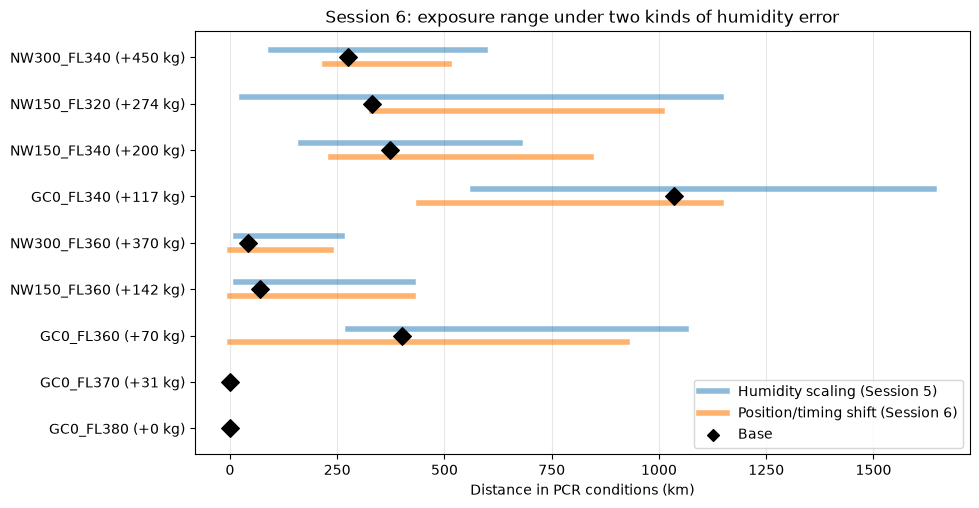

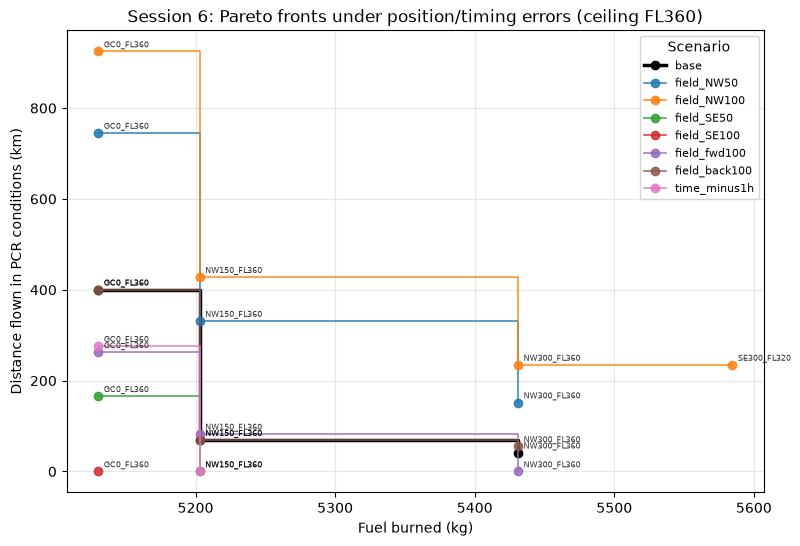

In [6]:
# 1. Exposure range for key routes: displacement (orange) vs humidity scaling (blue)
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, r in enumerate(key):
    ax.plot([pcr5.loc[r].min(), pcr5.loc[r].max()], [i + 0.15] * 2, color="tab:blue", linewidth=4, alpha=0.5)
    ax.plot([pcr6.loc[r].min(), pcr6.loc[r].max()], [i - 0.15] * 2, color="tab:orange", linewidth=4, alpha=0.6)
    ax.scatter(pcr6.at[r, "base"], i, s=80, marker="D", color="k", zorder=4)
ax.plot([], [], color="tab:blue", linewidth=4, alpha=0.5, label="Humidity scaling (Session 5)")
ax.plot([], [], color="tab:orange", linewidth=4, alpha=0.6, label="Position/timing shift (Session 6)")
ax.scatter([], [], marker="D", color="k", label="Base")
ax.set_yticks(range(len(key)))
ax.set_yticklabels([f"{r} (+{fuel[r] - fuel.min():.0f} kg)" for r in key])
ax.set_xlabel("Distance in PCR conditions (km)")
ax.set_title("Session 6: exposure range under two kinds of humidity error")
ax.grid(alpha=0.3, axis="x")
ax.legend(loc="lower right")
fig.savefig(fig_dir / "session6_exposure_ranges.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Pareto fronts per displacement scenario, ceiling FL360
cands = m4.index[m4["flight_level"] <= 360]
fig, ax = plt.subplots(figsize=(9, 6))
for scen in pcr6.columns:
    sub = pd.DataFrame({"fuel_kg": fuel.loc[cands], "pcr_km": pcr6.loc[cands, scen]})
    f = sub[pareto_mask(sub)].sort_values("fuel_kg")
    style = dict(linewidth=2.5, color="k") if scen == "base" else dict(linewidth=1.2, alpha=0.85)
    ax.step(f["fuel_kg"], f["pcr_km"], where="post", marker="o", label=scen, **style)
    for r, row in f.iterrows():
        ax.annotate(r, (row["fuel_kg"], row["pcr_km"]), textcoords="offset points",
                    xytext=(4, 3), fontsize=6, alpha=0.8)
ax.set_xlabel("Fuel burned (kg)")
ax.set_ylabel("Distance flown in PCR conditions (km)")
ax.set_title("Session 6: Pareto fronts under position/timing errors (ceiling FL360)")
ax.grid(alpha=0.3)
ax.legend(title="Scenario", fontsize=8)
fig.savefig(fig_dir / "session6_fronts_by_displacement_FL360.png", dpi=150, bbox_inches="tight")
plt.show()

## Results

### Setup

The ERA5 temperature and humidity field over the region was displaced in
space or time, and the 40 Session 4 routes were re-evaluated with PCR.
Displacements were defined relative to the route direction, since the moist
band lies roughly along the route:

| Scenario | Displacement |
|---|---|
| `field_NW50` / `field_NW100` | 50 / 100 km perpendicular, towards the north-west (the detour side) |
| `field_SE50` / `field_SE100` | 50 / 100 km perpendicular, towards the south-east |
| `field_fwd100` / `field_back100` | 100 km along / against the direction of flight |
| `time_minus1h` | weather arrives 1 h early (field at t = ERA5 at t + 1 h) |

### Checks

a zero-displacement copy of the regional field reproduces
Session 4 exactly (max difference 0.000000 km), so cutting out and
rebuilding the field changes nothing by itself. All shifted fields cover
every route in space and time; there were no missing values in 320 route
evaluations.

### Findings

#### Exposure under displacement (km in PCR conditions)

| Route | Base | NW 50 | NW 100 | SE 50 | SE 100 | Fwd 100 | Back 100 | −1 h |
|---|---|---|---|---|---|---|---|---|
| GC0_FL380, GC0_FL370 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 |
| GC0_FL360 | 400 | 745 | 925 | 166 | 0 | 262 | 400 | 276 |
| NW150_FL360 | 69 | 331 | 428 | 0 | 0 | 83 | 69 | 0 |
| NW300_FL360 | 41 | 152 | 235 | 0 | 0 | 0 | 55 | 0 |
| GC0_FL340 | 1,035 | 1,145 | 1,076 | 731 | 442 | 1,090 | 980 | 1,090 |
| NW150_FL340 | 373 | 662 | 842 | 235 | 386 | 400 | 386 | 373 |
| NW150_FL320 | 331 | 925 | 1,007 | 428 | 662 | 442 | 580 | 414 |
| NW300_FL340 | 276 | 317 | 511 | 345 | 400 | 497 | 221 | 483 |

- **All FL370 and FL380 routes stay contrail-free under every
  displacement.** Combined with Session 5, the altitude option is clean in
  all 12 distinct scenarios tested.
- **Moving the moist field towards the detour side hurts most.** With the
  field 100 km north-west, NW150_FL360 rises from 69 to 428 km and
  NW150_FL320 from 331 to 1,007 km.
- **At FL360, the 150 km detour is never worse than the great circle.** It
  cuts exposure by 54–100% in every scenario where the great circle has
  any.

#### Does the best route change?

Yes. Displacement reorders routes, which uniform humidity scaling did not.
Best route per scenario, for J = fuel + λ·(PCR km):

- **Ceiling FL380:** GC0_FL380 in every scenario, for every λ.
- **Ceiling FL360:** stable at λ = 0.1 (GC0_FL360). At λ = 1, NW150_FL360
  except with the field 100 km SE, where the great circle is already clean.
  At λ = 10, it varies between NW300, NW150 and GC0 at FL360.
- **Ceiling FL340, λ = 1:** NW150_FL340 (base), NW300_FL340 (field NW
  50 km), **SE300_FL320** (field NW 100 km), GC0_FL340 (field SE 100 km).
  If the moist band moves, the dry side can switch from north-west to
  south-east.

#### Robust choice

The deterministic, worst-case and minimax-regret rules from Session 5 were
applied to the displacement scenarios alone, and to all 12 distinct
scenarios combined (5 humidity scalings + 7 displacements; `boost` is
excluded as identical to `rhi_x1.03`).

- **The rules disagree in only 1 of 18 cases:** ceiling FL340, λ = 1,
  displacement set.
  - Deterministic and minimax regret choose NW150_FL340 (worst case 842 km,
    with the field 100 km NW; max regret 283 kg-equivalent).
  - Worst-case robust chooses NW300_FL340 (worst case 511 km) for 249 kg
    extra fuel.
- **In the combined set, the rules agree everywhere.** At ceiling FL340 and
  λ = 1, the worst-case rule prefers NW150_FL340 over NW300_FL340 by under
  1 kg-equivalent, which is effectively a tie.
- **Session 5's one disagreement (ceiling FL340, λ = 0.1) disappears in the
  combined set.** Position errors worsen the robust alternative's own worst
  case. Which route is "robust" depends on which errors are planned for.

### Interpretation

Position and timing errors are a harder test than uniform humidity scaling:
they change which route is best, and can switch the dry side of the band.
Even so, the route chosen from the base data remains a reasonable choice
across almost all scenarios. Robust rules depart from it in one case, at a
fuel cost of 249 kg (+4.7%). The most robust decision available is
unchanged from Sessions 4 and 5: when FL370 or above is reachable, climbing
removes contrail exposure in every scenario tested. Lateral avoidance is
useful but its benefit is uncertain, especially at FL340 and below.

This session does not move the moist layer up or down; Session 7 tests vertical errors.

### Corrections

**Fuel (found in Session 7).** The fuel values used in the decisions above were slightly biased (see `06_vertical_and_mass.ipynb`, section 6). Recomputed with corrected fuel, none of the chosen routes changes; the worst-case rule's extra fuel at ceiling FL340, λ = 1 becomes 248.4 kg instead of 249 kg. Contrail exposure is unaffected.

### Limitations

- Displacements are rigid shifts of the whole field. Real errors also
  change the shape and intensity of supersaturated regions.
- Scenarios are equally weighted sensitivity cases, not probabilities.
- Fuel uses the undisplaced (Session 4) temperatures.
- Only a −1 h timing error was tested; +1 h would need ERA5 data before
  00:00.
- One flight, one date, one departure time.